# 3.1 — Document Ingestion & Chunking
### PDF processing · Chunking strategies · `RecursiveCharacterTextSplitter`

**Course:** Python & Generative AI (BTech, Sem 3) · **Duration:** ~90 min · **Instructor:** Stride School of Business

---

**Learning outcomes** — by the end of this notebook students can:

1. Explain where *ingestion* and *chunking* sit inside a RAG (Retrieval-Augmented Generation) pipeline.
2. Load a PDF, extract text page-by-page, and keep **metadata** (source, page number).
3. Clean extracted text (hyphenation, headers/footers, broken line wraps).
4. Explain *why* we chunk (context windows, retrieval precision, cost).
5. Use `RecursiveCharacterTextSplitter` and tune `chunk_size`, `chunk_overlap`, `separators`.
6. Compare fixed-size, recursive, token-based and **semantic (embedding-similarity)** chunking with charts.
7. Evaluate chunk quality and export chunks ready for embedding.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup | 5 min |
| 1 | The big picture: RAG pipeline | 10 min |
| 2 | PDF ingestion | 20 min |
| 3 | Why chunk? | 10 min |
| 4 | `RecursiveCharacterTextSplitter` deep-dive | 25 min |
| 5 | Semantic chunking & comparison | 15 min |
| 6 | Exercises, quiz, cheat-sheet | 5 min + homework |

## Part 0 — Setup
Run once. Everything in this notebook works **offline** — we generate our own sample PDF, so no API keys are needed.

In [1]:
# Uncomment on a fresh machine / Colab
# !pip install -q langchain-text-splitters langchain-core pypdf reportlab matplotlib scikit-learn

In [2]:
import re, json, textwrap, statistics
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

from pypdf import PdfReader
from langchain_core.documents import Document
from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
PALETTE = ["#2E86AB", "#F18F01", "#C73E1D", "#3B8B5A", "#6C4AB6", "#8C8C8C"]
print("✅ Imports OK")

✅ Imports OK


## Part 1 — The Big Picture: where does ingestion fit?

An LLM only knows what it was trained on. **RAG** lets it answer questions about *your* documents by retrieving relevant passages and putting them in the prompt.

Ingestion + chunking is the **offline indexing** half of RAG. If this step is bad, *nothing downstream can fix it* — "garbage in, garbage out".

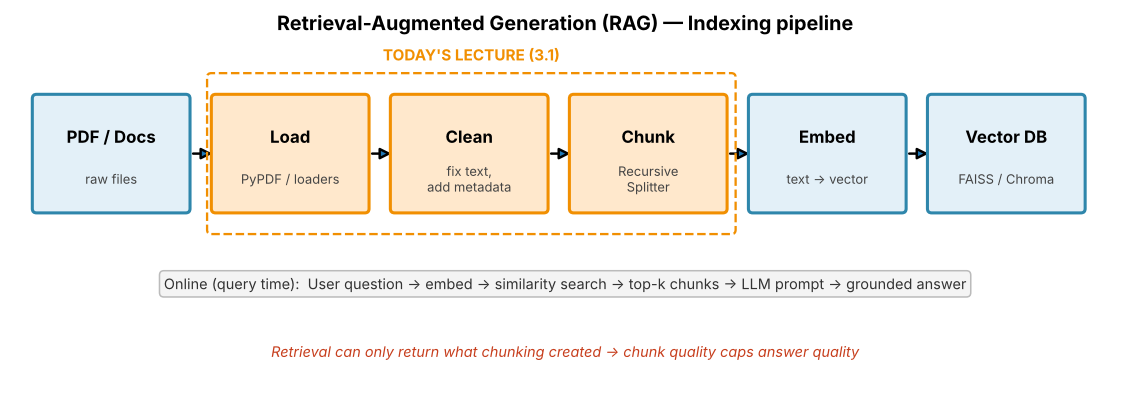

In [3]:
def draw_pipeline():
    fig, ax = plt.subplots(figsize=(13, 4.2))
    ax.set_xlim(0, 13); ax.set_ylim(0, 4.2); ax.axis("off")
    stages = [("PDF / Docs", "raw files"), ("Load", "PyPDF / loaders"),
              ("Clean", "fix text,\nadd metadata"), ("Chunk", "Recursive\nSplitter"),
              ("Embed", "text → vector"), ("Vector DB", "FAISS / Chroma")]
    for i, (t, s) in enumerate(stages):
        x = 0.3 + i * 2.1
        hl = t in ("Load", "Clean", "Chunk")
        box = FancyBboxPatch((x, 2.2), 1.75, 1.3, boxstyle="round,pad=0.05",
                             fc="#FFE8CC" if hl else "#E3F0F8",
                             ec=PALETTE[1] if hl else PALETTE[0], lw=2)
        ax.add_patch(box)
        ax.text(x + .875, 3.05, t, ha="center", va="center", weight="bold", fontsize=11)
        ax.text(x + .875, 2.55, s, ha="center", va="center", fontsize=8.5, color="#444")
        if i < len(stages) - 1:
            ax.add_patch(FancyArrowPatch((x + 1.8, 2.85), (x + 2.1, 2.85),
                                         arrowstyle="-|>", mutation_scale=15, lw=1.6))
    ax.add_patch(FancyBboxPatch((2.35, 1.95), 6.1, 1.8, boxstyle="round,pad=0.05",
                                fc="none", ec=PALETTE[1], lw=1.5, ls="--"))
    ax.text(5.4, 3.95, "TODAY'S LECTURE (3.1)", ha="center", color=PALETTE[1], weight="bold")
    # query path
    ax.text(6.5, 1.25, "Online (query time):  User question → embed → similarity search → top-k chunks → LLM prompt → grounded answer",
            ha="center", fontsize=9.5, color="#333",
            bbox=dict(boxstyle="round", fc="#F4F4F4", ec="#BBB"))
    ax.text(6.5, 0.45, "Retrieval can only return what chunking created → chunk quality caps answer quality",
            ha="center", fontsize=9.5, style="italic", color=PALETTE[2])
    ax.set_title("Retrieval-Augmented Generation (RAG) — Indexing pipeline", fontsize=13, weight="bold")
    plt.show()
draw_pipeline()

## Part 2 — PDF Ingestion

### 2.1 What is actually inside a PDF?
A PDF is **not** a text file. It is a set of drawing instructions: *"put glyph 'R' at (x=72, y=700) in font Helvetica 11pt"*. There are no real paragraphs, no reading order, no tables — the extractor has to **reconstruct** them.

| PDF type | What you get | Tool |
|---|---|---|
| Digital (born-digital, e.g. Word → PDF) | Text layer exists ✅ | `pypdf`, `PyMuPDF`, `pdfplumber` |
| Scanned (photo of paper) | Only images ❌ | OCR: `pytesseract`, `unstructured`, cloud OCR |
| Complex layout (tables, 2 columns) | Text extracted but order may break ⚠️ | `pdfplumber`, `unstructured`, `docling` |

**Common extraction problems:** repeated headers/footers, page numbers, hyphenated words (`informa-\ntion`), hard line-breaks mid-sentence, ligatures (`ﬁ`), multi-column jumbling.

### 2.2 Create a sample PDF
So everyone has the same input, we generate a small 4-page "AI Policy Handbook" with headings, paragraphs, a list, a header and a footer (with page numbers) — deliberately including the messy bits.

In [4]:
from reportlab.lib.pagesizes import A4
from reportlab.pdfgen import canvas

SECTIONS = [
 ("1. Introduction to Artificial Intelligence",
  ["Artificial Intelligence (AI) refers to computer systems that perform tasks normally requiring human intelligence, such as understanding language, recognising images and making decisions. Modern AI is dominated by machine learning, where systems learn patterns from data instead of following hand-written rules.",
   "Large Language Models (LLMs) are a family of machine learning models trained on huge amounts of text. They predict the next token in a sequence, and this simple objective gives rise to surprisingly general abilities such as summarisation, translation and question answering."]),
 ("2. Retrieval-Augmented Generation",
  ["LLMs have a knowledge cut-off and cannot read your private documents. Retrieval-Augmented Generation (RAG) solves this by retrieving relevant passages from a document store and inserting them into the prompt. The model then answers using the retrieved evidence, which reduces hallucination.",
   "A RAG system has two phases. In the indexing phase, documents are loaded, cleaned, split into chunks, converted into embeddings and stored in a vector database. In the query phase, the user question is embedded and the most similar chunks are retrieved."]),
 ("3. Data Privacy and Responsible Use",
  ["Students and staff must not upload confidential, personal or examination data to public AI tools. Personal data includes names, roll numbers, phone numbers, grades and health information. When in doubt, anonymise the data before using any external service.",
   "Key rules for responsible use:",
   "- Always disclose when AI assistance was used in an assignment.",
   "- Verify every factual claim produced by an AI model.",
   "- Never present AI-generated work as entirely your own.",
   "Violations of this policy will be handled under the academic integrity framework of the institution."]),
 ("4. Evaluating AI Outputs",
  ["AI outputs should be evaluated for accuracy, relevance, bias and safety. Accuracy can be checked against trusted sources. Relevance measures whether the answer addresses the question that was actually asked.",
   "Bias appears when a model systematically favours or disadvantages certain groups. Safety evaluation checks that the model does not produce harmful, illegal or dangerous content. A good practice is to keep a small test set of questions with known answers and re-run it whenever the system changes."]),
]

def make_pdf(path="ai_policy_handbook.pdf"):
    c = canvas.Canvas(path, pagesize=A4)
    W, H = A4
    for page_no, (title, paras) in enumerate(SECTIONS, start=1):
        c.setFont("Helvetica-Oblique", 8)
        c.drawString(50, H - 30, "Stride School of Business - AI Policy Handbook (Draft v1.2)")   # header
        c.drawRightString(W - 50, 25, f"Page {page_no} of {len(SECTIONS)}")                     # footer
        y = H - 80
        c.setFont("Helvetica-Bold", 14); c.drawString(50, y, title); y -= 28
        c.setFont("Helvetica", 11)
        for p in paras:
            for line in textwrap.wrap(p, 88):        # hard line-breaks, like real PDFs
                c.drawString(50, y, line); y -= 15
            y -= 10
        c.showPage()
    c.save()
    return path

PDF_PATH = make_pdf()
print("Created:", PDF_PATH, "|", Path(PDF_PATH).stat().st_size, "bytes")

Created: ai_policy_handbook.pdf | 5349 bytes


### 2.3 Load the PDF with `pypdf`
We read **page by page** and wrap each page in a LangChain `Document` with `page_content` + `metadata`. Metadata is what lets the final answer say *"source: handbook.pdf, page 3"* — crucial for trust and citations.

In [5]:
reader = PdfReader(PDF_PATH)
print("Pages:", len(reader.pages))
print("PDF metadata:", reader.metadata)

raw_docs = []
for i, page in enumerate(reader.pages):
    text = page.extract_text() or ""
    raw_docs.append(Document(page_content=text,
                             metadata={"source": PDF_PATH, "page": i + 1}))

print("\n--- RAW text of page 3 (note header, footer, hard line breaks) ---\n")
print(raw_docs[2].page_content)

Pages: 4
PDF metadata: {'/Author': 'anonymous', '/CreationDate': "D:20261120032417+00'00'", '/Creator': 'anonymous', '/Keywords': '', '/ModDate': "D:20261120032417+00'00'", '/Producer': 'ReportLab PDF Library - (opensource)', '/Subject': 'unspecified', '/Title': 'untitled', '/Trapped': '/False'}

--- RAW text of page 3 (note header, footer, hard line breaks) ---

Stride School of Business - AI Policy Handbook (Draft v1.2)
Page 3 of 4
3. Data Privacy and Responsible Use
Students and staff must not upload confidential, personal or examination data to public
AI tools. Personal data includes names, roll numbers, phone numbers, grades and health
information. When in doubt, anonymise the data before using any external service.
Key rules for responsible use:
- Always disclose when AI assistance was used in an assignment.
- Verify every factual claim produced by an AI model.
- Never present AI-generated work as entirely your own.
Violations of this policy will be handled under the academic int

> 💡 **LangChain shortcut.** The same thing in one line (needs `langchain-community`):
> ```python
> from langchain_community.document_loaders import PyPDFLoader
> raw_docs = PyPDFLoader("ai_policy_handbook.pdf").load()   # one Document per page
> ```
> Other loaders: `PyMuPDFLoader` (fast), `PDFPlumberLoader` (tables), `UnstructuredPDFLoader` (layout + OCR).
> We wrote it by hand above so students see **exactly** what a loader does.

### 2.4 Clean the text
Rule of thumb: **clean before you chunk**. Noise inside chunks wastes tokens and confuses embeddings (every chunk would "match" the word *Handbook* because of the header!).

In [6]:
HEADER_RE = re.compile(r"^Stride School of Business - AI Policy Handbook.*$", re.M)
FOOTER_RE = re.compile(r"^Page \d+ of \d+\s*$", re.M)

def clean_text(t: str) -> str:
    t = HEADER_RE.sub("", t)                       # 1. drop running header
    t = FOOTER_RE.sub("", t)                       # 2. drop page numbers
    t = t.replace("ﬁ", "fi").replace("ﬂ", "fl")   # 3. ligatures
    t = re.sub(r"(\w)-\n([a-z])", r"\1\2", t)      # 4. de-hyphenate "informa-\ntion" (keep "Retrieval-Augmented")
    t = re.sub(r"(\w)-\n([A-Z])", r"\1-\2", t)     # 4a. real hyphen at line end: just remove the break
    t = re.sub(r"(?m)^(\d+\.\s[^\n]*[^.\n])\n", r"\1\n\n", t)  # 4b. numbered headings stay on their own
    t = re.sub(r"\n(?=- )", "\n\n", t)             # 5. keep bullet items on own lines
    t = re.sub(r"(?<![.:!?\n])\n(?!\n|- )", " ", t)  # 6. join wrapped lines inside a sentence
    t = re.sub(r"(?<=[.:!?])\n(?=[A-Z0-9])", "\n\n", t)  # 7. sentence-end + newline -> paragraph break
    t = re.sub(r"[ \t]+", " ", t)                  # 8. collapse spaces
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

docs = [Document(page_content=clean_text(d.page_content), metadata=d.metadata) for d in raw_docs]
print(docs[2].page_content)

3. Data Privacy and Responsible Use

Students and staff must not upload confidential, personal or examination data to public AI tools. Personal data includes names, roll numbers, phone numbers, grades and health information. When in doubt, anonymise the data before using any external service.

Key rules for responsible use:

- Always disclose when AI assistance was used in an assignment.

- Verify every factual claim produced by an AI model.

- Never present AI-generated work as entirely your own.

Violations of this policy will be handled under the academic integrity framework of the institution.


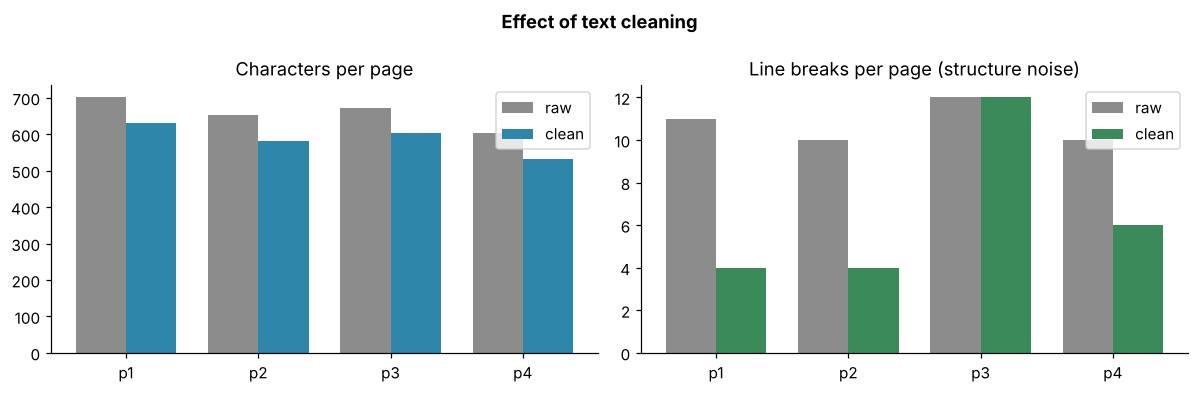

In [7]:
# Visualise: how much noise did cleaning remove?
raw_len   = [len(d.page_content) for d in raw_docs]
clean_len = [len(d.page_content) for d in docs]
raw_nl    = [d.page_content.count("\n") for d in raw_docs]
clean_nl  = [d.page_content.count("\n") for d in docs]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(len(docs)); w = .38
axes[0].bar(x - w/2, raw_len, w, label="raw", color=PALETTE[5])
axes[0].bar(x + w/2, clean_len, w, label="clean", color=PALETTE[0])
axes[0].set_title("Characters per page"); axes[0].set_xticks(x, [f"p{i+1}" for i in x]); axes[0].legend()
axes[1].bar(x - w/2, raw_nl, w, label="raw", color=PALETTE[5])
axes[1].bar(x + w/2, clean_nl, w, label="clean", color=PALETTE[3])
axes[1].set_title("Line breaks per page (structure noise)"); axes[1].set_xticks(x, [f"p{i+1}" for i in x]); axes[1].legend()
plt.suptitle("Effect of text cleaning", weight="bold"); plt.tight_layout(); plt.show()

## Part 3 — Why do we chunk at all?

Why not embed the whole PDF as one vector?

1. **Context-window & cost** — you pay per token; sending a 300-page manual for every question is slow and expensive.
2. **Embedding dilution** — one vector for a whole document is an *average* of many topics → it matches nothing well.
3. **Retrieval precision** — small focused chunks let the retriever return *exactly* the paragraph that answers the question.
4. **Citations** — chunks carry page metadata → traceable answers.

But chunks that are **too small** lose context ("*it* must not be uploaded" — what is *it*?).

> 🎯 **Goal of chunking:** each chunk should be a **self-contained unit of meaning** — big enough to make sense alone, small enough to be about one thing.

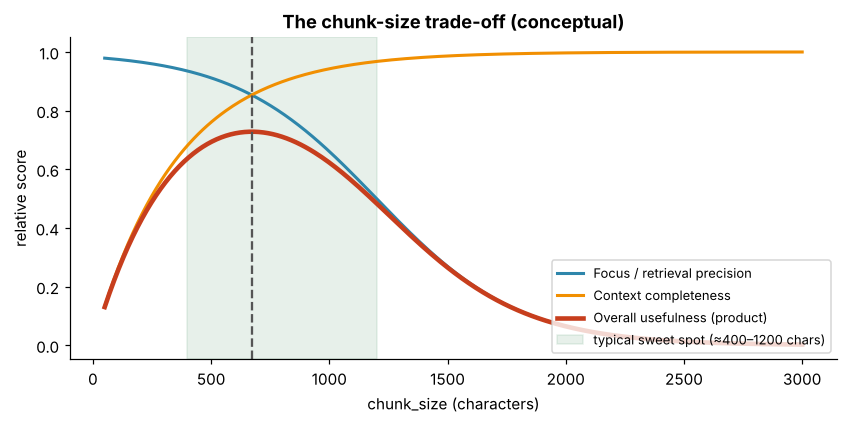

In [8]:
# Conceptual chart: the chunk-size trade-off (illustrative curves, not measured data)
s = np.linspace(50, 3000, 300)
precision = 1 / (1 + np.exp((s - 1200) / 300))          # topic focus falls as chunks grow
context   = 1 - np.exp(-s / 350)                        # self-containedness rises
quality   = precision * context
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(s, precision, label="Focus / retrieval precision", color=PALETTE[0], lw=2)
ax.plot(s, context, label="Context completeness", color=PALETTE[1], lw=2)
ax.plot(s, quality, label="Overall usefulness (product)", color=PALETTE[2], lw=3)
best = s[quality.argmax()]
ax.axvspan(400, 1200, color=PALETTE[3], alpha=.12, label="typical sweet spot (≈400–1200 chars)")
ax.axvline(best, ls="--", color="#555")
ax.set_xlabel("chunk_size (characters)"); ax.set_ylabel("relative score")
ax.set_title("The chunk-size trade-off (conceptual)", weight="bold"); ax.legend(loc="lower right", fontsize=8.5)
plt.show()

### 3.1 Naïve approach: fixed-size slicing
Cut every *N* characters — simple, but it slices words and sentences in half.

In [9]:
full_text = "\n\n".join(d.page_content for d in docs)
N = 200
naive = [full_text[i:i+N] for i in range(0, len(full_text), N)]
for i, ch in enumerate(naive[:4]):
    print(f"[{i}] ...{ch[-40:]!r}  ⟶ next starts {naive[i+1][:25]!r}")

[0] ...'ch as understanding language, recognisin'  ⟶ next starts 'g images and making decis'
[1] ...'e Language Models (LLMs) are a family of'  ⟶ next starts ' machine learning models '
[2] ...'l abilities such as summarisation, trans'  ⟶ next starts 'lation and question answe'
[3] ...'eration (RAG) solves this by retrieving '  ⟶ next starts 'relevant passages from a '


👀 Notice the chunks end **mid-word** (`'...persona'` / `'l data'`). An embedding of half a word is noise. We need a splitter that respects language structure.

## Part 4 — `RecursiveCharacterTextSplitter` (the default you should reach for)

### 4.1 The algorithm
It tries a **priority list of separators**, from the most "semantic" boundary to the least:

```
["\n\n",  "\n",  " ",  ""]
 paragraph → line → word → character
```

1. Split the text on the **first** separator (`\n\n` = paragraphs).
2. Greedily **merge** neighbouring pieces back together while they fit within `chunk_size`.
3. Any piece that is *still* bigger than `chunk_size` is **recursively** split with the **next** separator.
4. Consecutive chunks share `chunk_overlap` characters so meaning that crosses a boundary isn't lost.

So it only "breaks a sentence" when it truly has to — that's why it is called *structure-aware* (a cheap approximation of semantic chunking).

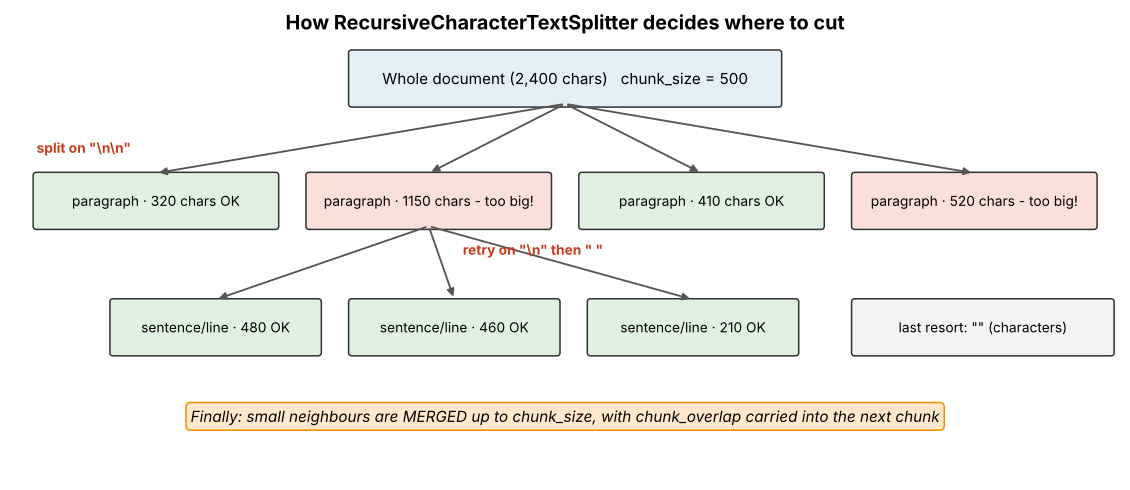

In [10]:
def draw_recursive_tree():
    fig, ax = plt.subplots(figsize=(13, 5.2)); ax.axis("off"); ax.set_xlim(0, 13); ax.set_ylim(0, 5.4)
    def box(x, y, w, t, c, fs=9):
        ax.add_patch(FancyBboxPatch((x, y), w, .62, boxstyle="round,pad=0.04", fc=c, ec="#333", lw=1))
        ax.text(x + w/2, y + .31, t, ha="center", va="center", fontsize=fs)
    def arrow(x1, y1, x2, y2, lbl=""):
        ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="-|>", lw=1.2, color="#555"))
        if lbl: ax.text((x1+x2)/2 + .08, (y1+y2)/2, lbl, fontsize=8, color=PALETTE[2])
    box(4.0, 4.6, 5, "Whole document (2,400 chars)   chunk_size = 500", "#E3F0F8", 10)
    xs = [0.3, 3.5, 6.7, 9.9]; sizes = [320, 1150, 410, 520]
    for x, sz in zip(xs, sizes):
        arrow(6.5, 4.6, x + 1.4, 3.75, "")
        ok = sz <= 500
        box(x, 3.1, 2.8, f"paragraph · {sz} chars " + ("OK" if ok else "- too big!"), "#DFF2E1" if ok else "#FBE0DA")
    ax.text(.3, 4.0, 'split on "\\n\\n"', color=PALETTE[2], fontsize=9, weight="bold")
    for i, (x, sz) in enumerate([(1.2, 480), (4.0, 460), (6.8, 210)]):
        arrow(4.9, 3.1, x + 1.2, 2.2)
        box(x, 1.55, 2.4, f"sentence/line · {sz} OK", "#DFF2E1")
    ax.text(5.3, 2.75, 'retry on "\\n" then " "', color=PALETTE[2], fontsize=9, weight="bold")
    box(9.9, 1.55, 3.0, 'last resort: "" (characters)', "#F4F4F4")
    ax.text(6.5, .7, "Finally: small neighbours are MERGED up to chunk_size, with chunk_overlap carried into the next chunk",
            ha="center", fontsize=10, style="italic",
            bbox=dict(boxstyle="round", fc="#FFE8CC", ec=PALETTE[1]))
    ax.set_title("How RecursiveCharacterTextSplitter decides where to cut", weight="bold", fontsize=13)
    plt.show()
draw_recursive_tree()

### 4.2 Basic usage

In [11]:
splitter = RecursiveCharacterTextSplitter(
    chunk_size=400,          # max characters per chunk
    chunk_overlap=60,        # characters repeated between consecutive chunks
    separators=["\n\n", "\n", ". ", " ", ""],   # we add ". " so it prefers sentence ends
    length_function=len,     # how "size" is measured (characters here)
    add_start_index=True,    # store char offset of each chunk in metadata
)

chunks = splitter.split_documents(docs)     # keeps + copies page metadata ✅
print(f"{len(docs)} pages  →  {len(chunks)} chunks\n")
for c in chunks[:5]:
    print(f"📦 page={c.metadata['page']}  start={c.metadata['start_index']:>4}  len={len(c.page_content)}")
    print("   ", c.page_content[:150].replace("\n", " ⏎ "), "...\n")

4 pages  →  8 chunks

📦 page=1  start=   0  len=354
    1. Introduction to Artificial Intelligence ⏎  ⏎ Artificial Intelligence (AI) refers to computer systems that perform tasks normally requiring human intell ...

📦 page=1  start= 356  len=274
    Large Language Models (LLMs) are a family of machine learning models trained on huge amounts of text. They predict the next token in a sequence, and t ...

📦 page=2  start=   0  len=325
    2. Retrieval-Augmented Generation ⏎  ⏎ LLMs have a knowledge cut-off and cannot read your private documents. Retrieval-Augmented Generation (RAG) solves t ...

📦 page=2  start= 327  len=253
    A RAG system has two phases. In the indexing phase, documents are loaded, cleaned, split into chunks, converted into embeddings and stored in a vector ...

📦 page=3  start=   0  len=390
    3. Data Privacy and Responsible Use ⏎  ⏎ Students and staff must not upload confidential, personal or examination data to public AI tools. Personal data i ...



> **`split_text` vs `split_documents`**
> - `splitter.split_text(str)` → `list[str]` (loses metadata)
> - `splitter.split_documents(list[Document])` → `list[Document]` (**keeps** `source`, `page`) ← use this in RAG

### 4.3 Seeing the overlap

In [12]:
from IPython.display import HTML, display

def show_overlap(c1, c2):
    a, b = c1.page_content, c2.page_content
    k = next((k for k in range(min(len(a), len(b)), 0, -1) if a.endswith(b[:k])), 0)
    html = (f"<div style='font-family:monospace;font-size:12px;line-height:1.5'>"
            f"<b>Chunk A (end):</b> …{a[:-k][-160:] if k else a[-160:]}"
            f"<span style='background:#FFD580'>{a[-k:] if k else ''}</span><br><br>"
            f"<b>Chunk B (start):</b> <span style='background:#FFD580'>{b[:k]}</span>{b[k:k+160]}…"
            f"<br><br><i>Highlighted = {k} overlapping chars</i></div>")
    display(HTML(html))

# find a consecutive pair on the same page that overlaps
for a, b in zip(chunks, chunks[1:]):
    if a.metadata["page"] == b.metadata["page"]:
        show_overlap(a, b); break

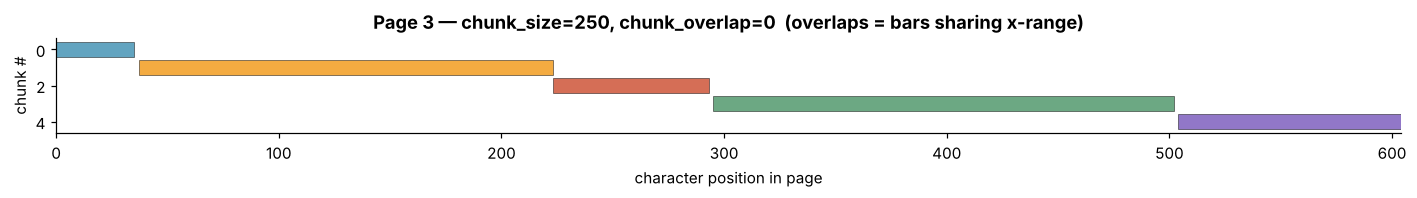

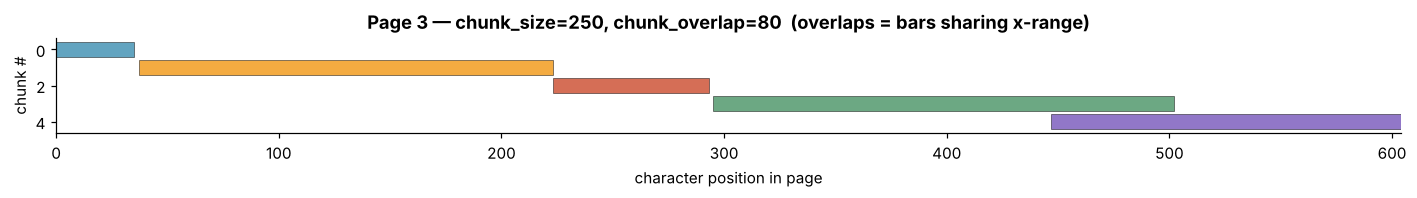

In [13]:
def draw_chunk_map(chs, text_len, title):
    fig, ax = plt.subplots(figsize=(13, 1.8 + .02*len(chs)))
    for i, c in enumerate(chs):
        s = c.metadata["start_index"]; e = s + len(c.page_content)
        ax.barh(i, e - s, left=s, color=PALETTE[i % 5], alpha=.75, edgecolor="k", lw=.4)
    ax.invert_yaxis(); ax.set_xlim(0, text_len)
    ax.set_xlabel("character position in page"); ax.set_ylabel("chunk #")
    ax.set_title(title, weight="bold"); plt.tight_layout(); plt.show()

page3 = [docs[2]]
for ov in (0, 80):
    sp = RecursiveCharacterTextSplitter(chunk_size=250, chunk_overlap=ov,
                                        separators=["\n\n", "\n", ". ", " ", ""], add_start_index=True)
    draw_chunk_map(sp.split_documents(page3), len(docs[2].page_content),
                   f"Page 3 — chunk_size=250, chunk_overlap={ov}  (overlaps = bars sharing x-range)")

### 4.4 Experiment: how `chunk_size` and `chunk_overlap` change the output

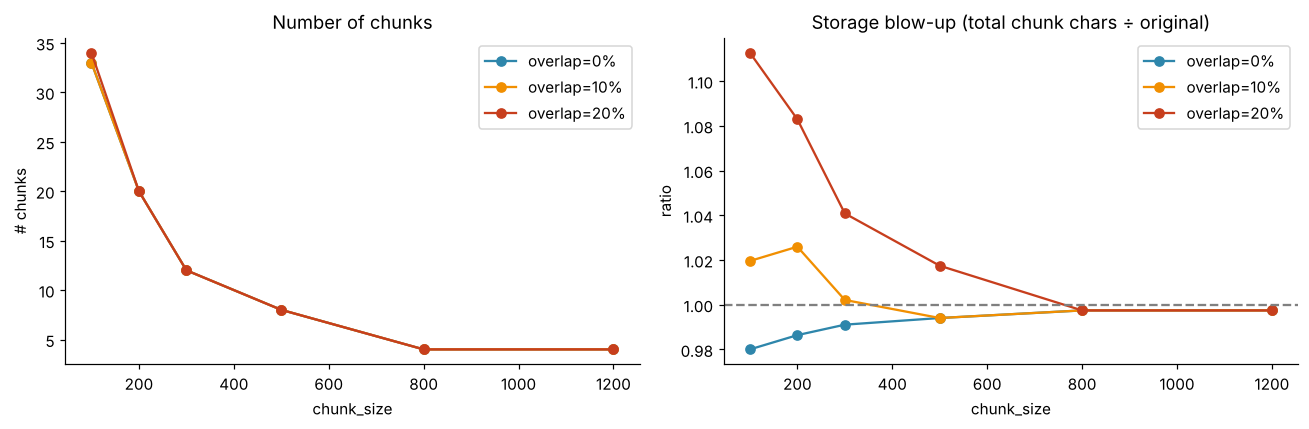

In [14]:
sizes    = [100, 200, 300, 500, 800, 1200]
overlaps = [0, 0.1, 0.2]           # as a fraction of chunk_size

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for j, frac in enumerate(overlaps):
    n_chunks, total_chars = [], []
    for cs in sizes:
        sp = RecursiveCharacterTextSplitter(chunk_size=cs, chunk_overlap=int(cs*frac))
        ch = sp.split_documents(docs)
        n_chunks.append(len(ch)); total_chars.append(sum(len(c.page_content) for c in ch))
    axes[0].plot(sizes, n_chunks, "o-", color=PALETTE[j], label=f"overlap={int(frac*100)}%")
    axes[1].plot(sizes, np.array(total_chars)/len(full_text), "o-", color=PALETTE[j], label=f"overlap={int(frac*100)}%")
axes[0].set(title="Number of chunks", xlabel="chunk_size", ylabel="# chunks")
axes[1].set(title="Storage blow-up (total chunk chars ÷ original)", xlabel="chunk_size", ylabel="ratio")
axes[1].axhline(1, ls="--", c="grey")
for a in axes: a.legend()
plt.tight_layout(); plt.show()

**Read the charts with students:**
- Smaller `chunk_size` → many more chunks → more embedding calls & vectors to store.
- Overlap costs storage (ratio > 1) — 10–20 % is the usual compromise.
- Note that `chunk_size` is a **maximum**, not a target — the splitter prefers clean boundaries, so most chunks come out *smaller*.

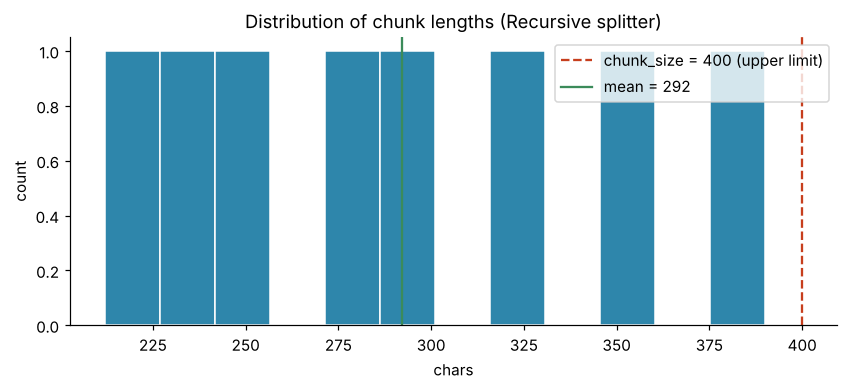

In [15]:
sp = RecursiveCharacterTextSplitter(chunk_size=400, chunk_overlap=40, separators=["\n\n", "\n", ". ", " ", ""])
lens_rec = [len(c.page_content) for c in sp.split_documents(docs)]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(lens_rec, bins=12, color=PALETTE[0], edgecolor="white")
ax.axvline(400, c=PALETTE[2], ls="--", label="chunk_size = 400 (upper limit)")
ax.axvline(np.mean(lens_rec), c=PALETTE[3], ls="-", label=f"mean = {np.mean(lens_rec):.0f}")
ax.set(title="Distribution of chunk lengths (Recursive splitter)", xlabel="chars", ylabel="count"); ax.legend()
plt.show()

### 4.5 Do separators matter? `CharacterTextSplitter` vs `RecursiveCharacterTextSplitter`
We count how many chunks **end cleanly** (on `.`, `:` or end of a paragraph) vs mid-sentence.

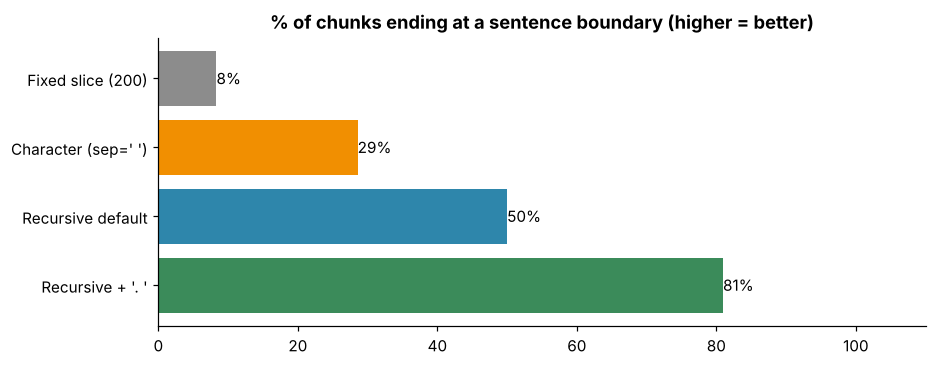

In [16]:
def clean_end_ratio(chs):
    ok = sum(1 for c in chs if c.page_content.rstrip()[-1:] in ".:!?")
    return ok / len(chs)

cfgs = {
  "Fixed slice (200)": None,
  "Character (sep=' ')": CharacterTextSplitter(separator=" ", chunk_size=200, chunk_overlap=0),
  "Recursive default": RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=0),
  "Recursive + '. '": RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=0,
                         separators=["\n\n", "\n", ". ", " ", ""], keep_separator="end"),
}
names, ratios = [], []
for name, sp in cfgs.items():
    chs = [Document(page_content=t) for t in naive] if sp is None else sp.split_documents(docs)
    names.append(name); ratios.append(clean_end_ratio(chs) * 100)
fig, ax = plt.subplots(figsize=(9, 3.4))
b = ax.barh(names, ratios, color=[PALETTE[5], PALETTE[1], PALETTE[0], PALETTE[3]])
ax.bar_label(b, fmt="%.0f%%"); ax.set_xlim(0, 110); ax.invert_yaxis()
ax.set_title("% of chunks ending at a sentence boundary (higher = better)", weight="bold")
plt.show()

✅ Adding `". "` as a separator (with `keep_separator="end"` so the full stop stays with its sentence) makes chunks end on sentences far more often.

### 4.6 Measuring in **tokens** instead of characters
LLMs and embedding models have limits in *tokens* (≈ 4 English chars per token). For production, size chunks by tokens:

```python
# pip install tiktoken
splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base", chunk_size=256, chunk_overlap=32)
```
Below is a dependency-free approximation using a custom `length_function`.

In [17]:
approx_tokens = lambda s: max(1, round(len(s) / 4))       # rule of thumb: 1 token ≈ 4 chars
tok_splitter = RecursiveCharacterTextSplitter(chunk_size=100, chunk_overlap=15,
                                              length_function=approx_tokens)
tok_chunks = tok_splitter.split_documents(docs)
print(len(tok_chunks), "chunks; token sizes:", [approx_tokens(c.page_content) for c in tok_chunks][:12], "...")

8 chunks; token sizes: [88, 68, 81, 63, 98, 53, 58, 74] ...


### 4.7 Language / format-aware presets
The same class ships with separator lists for code and markup — great for indexing a codebase or Markdown notes.

In [18]:
from langchain_text_splitters import Language
print("Python separators:", RecursiveCharacterTextSplitter.get_separators_for_language(Language.PYTHON)[:6])
print("Markdown separators:", RecursiveCharacterTextSplitter.get_separators_for_language(Language.MARKDOWN)[:6])

py_code = '''
class Retriever:
    def __init__(self, k=3):
        self.k = k

    def search(self, query):
        return []

def build_index(docs):
    return Retriever()
'''
py_splitter = RecursiveCharacterTextSplitter.from_language(Language.PYTHON, chunk_size=80, chunk_overlap=0)
for c in py_splitter.split_text(py_code):
    print("-----\n" + c)

Python separators: ['\nclass ', '\ndef ', '\n\tdef ', '\n\n', '\n', ' ']
Markdown separators: ['\n#{1,6} ', '```\n', '\n\\*\\*\\*+\n', '\n---+\n', '\n___+\n', '\n\n']
-----
class Retriever:
    def __init__(self, k=3):
        self.k = k
-----
def search(self, query):
        return []
-----
def build_index(docs):
    return Retriever()


## Part 5 — Semantic chunking (meaning-based)

`RecursiveCharacterTextSplitter` uses **structure** (paragraphs, sentences). *Semantic chunking* uses **meaning**:

1. Split text into sentences.
2. Embed each sentence.
3. Compute similarity between consecutive sentences.
4. Where similarity **drops sharply** (topic shift) → start a new chunk.

In LangChain: `langchain_experimental.text_splitter.SemanticChunker(OpenAIEmbeddings())`. To stay offline we implement the same idea with **TF-IDF vectors** — the logic is identical, only the embedding model differs.

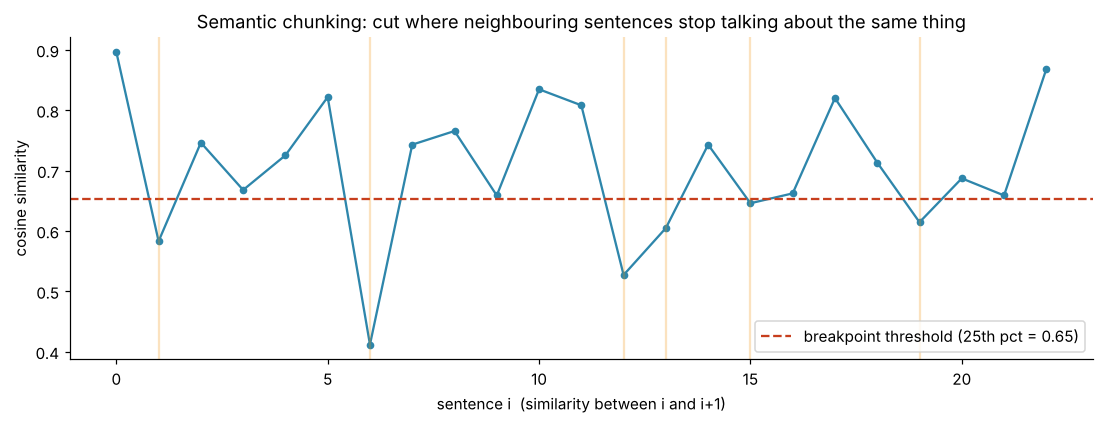

24 sentences → 7 semantic chunks

• Introduction to Artificial Intelligence  Artificial Intelligence (AI) refers to computer systems that perform tasks normally requiring human intelligence, such  ...

• Large Language Models (LLMs) are a family of machine learning models trained on huge amounts of text. They predict the next token in a sequence, and this simple ...

• A RAG system has two phases. In the indexing phase, documents are loaded, cleaned, split into chunks, converted into embeddings and stored in a vector database. ...

• Key rules for responsible use: ...



In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

sentences = [s.strip() for s in re.split(r"(?<=[.!?:])\s+", full_text.replace("\n", " ")) if len(s.strip()) > 3]
# Like LangChain's SemanticChunker(buffer_size=1): embed each sentence WITH its neighbours for stability
windows = [" ".join(sentences[max(0, i-1): i+2]) for i in range(len(sentences))]
vec = TfidfVectorizer(stop_words="english").fit_transform(windows)
sims = np.array([cosine_similarity(vec[i], vec[i+1])[0, 0] for i in range(len(sentences) - 1)])

threshold = np.percentile(sims, 25)          # breakpoints = lowest 25% similarities
breaks = [i for i, v in enumerate(sims) if v <= threshold]

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(sims, "o-", color=PALETTE[0], ms=4)
ax.axhline(threshold, color=PALETTE[2], ls="--", label=f"breakpoint threshold (25th pct = {threshold:.2f})")
for bpt in breaks: ax.axvline(bpt, color=PALETTE[1], alpha=.25)
ax.set(xlabel="sentence i  (similarity between i and i+1)", ylabel="cosine similarity",
       title="Semantic chunking: cut where neighbouring sentences stop talking about the same thing")
ax.legend(); plt.show()

sem_chunks, cur = [], [sentences[0]]
for i in range(len(sentences) - 1):
    if i in breaks: sem_chunks.append(" ".join(cur)); cur = []
    cur.append(sentences[i + 1])
sem_chunks.append(" ".join(cur))
print(f"{len(sentences)} sentences → {len(sem_chunks)} semantic chunks\n")
for c in sem_chunks[:4]: print("•", c[:160], "...\n")

### 5.1 Head-to-head comparison

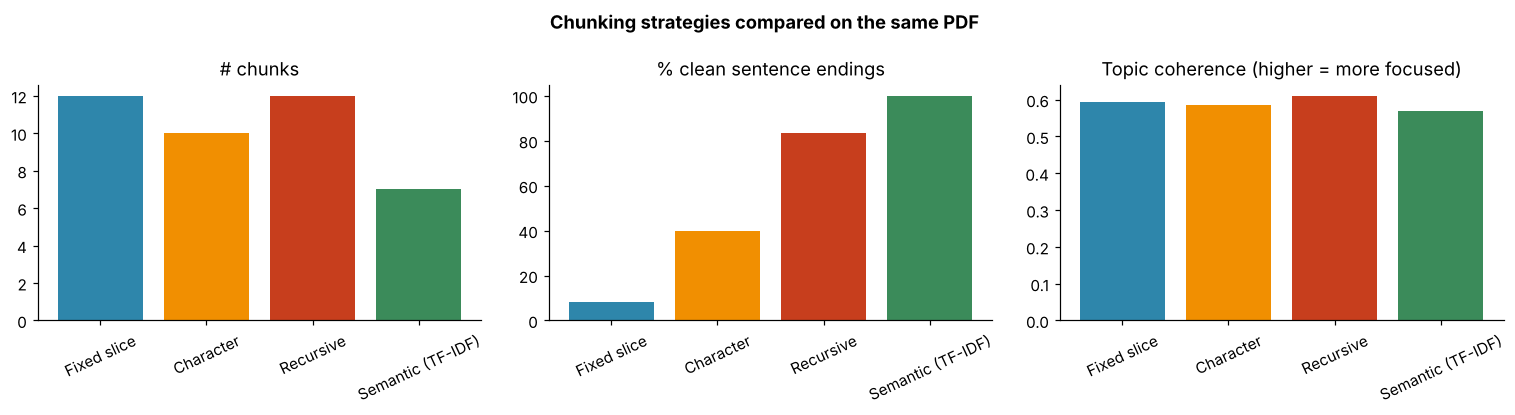

strategy             #  mean len     std  clean%  coherence
Fixed slice         12       196      13       8       0.59
Character           10       234     107      40       0.59
Recursive           12       194      93      83       0.61
Semantic (TF-IDF)    7       332     191     100       0.57


In [20]:
strategies = {
    "Fixed slice":   [t for t in naive],
    "Character":     [c.page_content for c in CharacterTextSplitter(separator=" ", chunk_size=300, chunk_overlap=0).split_documents(docs)],
    "Recursive":     [c.page_content for c in RecursiveCharacterTextSplitter(chunk_size=300, chunk_overlap=30,
                        separators=["\n\n", "\n", ". ", " ", ""], keep_separator="end").split_documents(docs)],
    "Semantic (TF-IDF)": sem_chunks,
}
def coherence(chs):
    # avg similarity of sentences inside a chunk to that chunk's centroid → "is the chunk about one thing?"
    tv = TfidfVectorizer(stop_words="english").fit(sentences); scores = []
    for c in chs:
        ss = [s for s in re.split(r"(?<=[.!?:])\s+", c) if len(s) > 3]
        if len(ss) < 2: continue
        m = tv.transform(ss); cen = np.asarray(m.mean(axis=0))
        scores.append(cosine_similarity(m, cen).mean())
    return np.mean(scores) if scores else 0

rows = []
for n, chs in strategies.items():
    L = [len(c) for c in chs]
    rows.append((n, len(chs), np.mean(L), np.std(L),
                 clean_end_ratio([Document(page_content=c) for c in chs]) * 100, coherence(chs)))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
labels = [r[0] for r in rows]; cols = PALETTE[:4]
axes[0].bar(labels, [r[1] for r in rows], color=cols); axes[0].set_title("# chunks")
axes[1].bar(labels, [r[4] for r in rows], color=cols); axes[1].set_title("% clean sentence endings")
axes[2].bar(labels, [r[5] for r in rows], color=cols); axes[2].set_title("Topic coherence (higher = more focused)")
for a in axes: a.tick_params(axis="x", rotation=25)
plt.suptitle("Chunking strategies compared on the same PDF", weight="bold"); plt.tight_layout(); plt.show()

print(f"{'strategy':<18}{'#':>4}{'mean len':>10}{'std':>8}{'clean%':>8}{'coherence':>11}")
for r in rows: print(f"{r[0]:<18}{r[1]:>4}{r[2]:>10.0f}{r[3]:>8.0f}{r[4]:>8.0f}{r[5]:>11.2f}")

| Strategy | How it cuts | ✅ Pros | ⚠️ Cons | Use when |
|---|---|---|---|---|
| Fixed-size | every N chars | trivial, predictable | breaks words/sentences | never in production |
| `CharacterTextSplitter` | one separator | simple | huge chunks if separator missing | uniform, well-formatted text |
| **`RecursiveCharacterTextSplitter`** | separator hierarchy | fast, robust, no model needed, keeps structure | doesn't "understand" topics | **default for 80% of RAG projects** |
| Token-based recursive | same, measured in tokens | matches model limits exactly | needs tokenizer | production w/ strict limits |
| Semantic | embedding-similarity drops | topic-coherent chunks | slower, costs embedding calls, variable sizes | long, mixed-topic documents |
| Document-structure (Markdown headers, HTML) | headings | preserves sections as metadata | needs structured source | docs, wikis, websites |

## Part 5.2 — Mini retrieval test: does chunking change the answer?
A tiny TF-IDF retriever lets students *see* the effect of chunk choice on what gets retrieved.

In [21]:
def retrieve(chunks_text, query, k=1):
    tv = TfidfVectorizer(stop_words="english").fit(chunks_text + [query])
    sims = cosine_similarity(tv.transform([query]), tv.transform(chunks_text))[0]
    idx = sims.argsort()[::-1][:k]
    return [(round(float(sims[i]), 3), chunks_text[i]) for i in idx]

query = "What personal data must students not upload to AI tools?"
for name in ["Fixed slice", "Recursive", "Semantic (TF-IDF)"]:
    score, txt = retrieve(strategies[name], query)[0]
    print(f"\n🔎 {name}  (score={score})\n   {txt[:300]}")


🔎 Fixed slice  (score=0.599)
   e retrieved.

3. Data Privacy and Responsible Use

Students and staff must not upload confidential, personal or examination data to public AI tools. Personal data includes names, roll numbers, phone n

🔎 Recursive  (score=0.532)
   3. Data Privacy and Responsible Use

Students and staff must not upload confidential, personal or examination data to public AI tools. Personal data includes names, roll numbers, phone numbers, grades and health information. When in doubt, anonymise the data before using any external service.

🔎 Semantic (TF-IDF)  (score=0.399)
   A RAG system has two phases. In the indexing phase, documents are loaded, cleaned, split into chunks, converted into embeddings and stored in a vector database. In the query phase, the user question is embedded and the most similar chunks are retrieved. Data Privacy and Responsible Use  Students and


**Discussion prompt:** Fixed slicing scores high but starts mid-word (`"re retrieved."`) and cuts off the answer. Recursive returns the complete, clean paragraph. Our crude TF-IDF semantic chunker merged the end of Section 2 with the start of Section 3 — semantic chunking is only as good as its embedding model (with real neural embeddings it does much better), which is why **Recursive is the robust default**.

## Part 5.3 — Export chunks (ready for embedding)
Each record = text + metadata + a stable id. This JSONL file is what you will feed into the **embedding & vector store** step in lecture 3.2.

In [22]:
final_splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=75,
                    separators=["\n\n", "\n", ". ", " ", ""], keep_separator="end", add_start_index=True)
final_chunks = final_splitter.split_documents(docs)
for i, c in enumerate(final_chunks):
    c.metadata["chunk_id"] = f"{Path(c.metadata['source']).stem}-p{c.metadata['page']}-c{i}"

with open("chunks.jsonl", "w") as f:
    for c in final_chunks:
        f.write(json.dumps({"text": c.page_content, **c.metadata}) + "\n")
print(f"Saved {len(final_chunks)} chunks → chunks.jsonl\n")
print(json.dumps({"text": final_chunks[0].page_content[:120] + "...", **final_chunks[0].metadata}, indent=2))

Saved 8 chunks → chunks.jsonl

{
  "text": "1. Introduction to Artificial Intelligence\n\nArtificial Intelligence (AI) refers to computer systems that perform tasks n...",
  "source": "ai_policy_handbook.pdf",
  "page": 1,
  "start_index": 0,
  "chunk_id": "ai_policy_handbook-p1-c0"
}


## Part 6 — Best-practice cheat-sheet 📌

1. **Inspect the raw text first** — print a page before you chunk. Scanned PDF? → OCR.
2. **Clean before chunking** — headers, footers, page numbers, hyphenation.
3. **Always keep metadata** (`source`, `page`, `chunk_id`) → citations & filtering.
4. Start with `RecursiveCharacterTextSplitter(chunk_size≈500–1000 chars / 200–400 tokens, chunk_overlap≈10–20 %)`.
5. Add `". "` to `separators` for prose; use `from_language()` for code.
6. Size in **tokens** for production (`from_tiktoken_encoder`).
7. Chunk size depends on the question type: **factoid Q&A → smaller**, **summaries/reasoning → larger**.
8. **Evaluate, don't guess** — build 10–20 test questions and compare retrieval for different settings.

---
## 🧪 Lab exercises
1. **Tune it:** Re-run 4.4 with `chunk_size=150` and `chunk_overlap=0`. Retrieve the query from 5.2. What breaks?
2. **Separators:** Remove `"\n\n"` from the separators list. How do the chunk boundaries in the chunk-map change?
3. **Your own PDF:** Replace `PDF_PATH` with a real PDF (e.g. a syllabus). Which cleaning rules do you need to add?
4. **Token budget:** Your embedding model accepts max 512 tokens. Configure a splitter that guarantees this, with 10 % overlap.
5. **Challenge:** Change the semantic threshold percentile (10, 30, 50). Plot #chunks vs percentile and explain the curve.

## ✅ Quick quiz
1. Why is embedding a whole 50-page document as one vector a bad idea?
2. In what order does `RecursiveCharacterTextSplitter` try its default separators?
3. What problem does `chunk_overlap` solve, and what does it cost?
4. Difference between `split_text` and `split_documents`?
5. When would you prefer semantic chunking over recursive chunking?

<details><summary><b>Answers (click)</b></summary>

1. The vector averages many topics, so it matches no specific question well; also the text is too large/expensive to put in a prompt.
2. `"\n\n"` → `"\n"` → `" "` → `""` (paragraph → line → word → character).
3. It preserves context that spans a chunk boundary; it costs extra storage/embedding and duplicate content.
4. `split_text` returns strings; `split_documents` returns `Document`s and preserves metadata.
5. Long documents with topic shifts that don't line up with formatting, when you can afford embedding calls at index time.
</details>

**Next lecture → 3.2: Embeddings & Vector Stores** (we load `chunks.jsonl` into FAISS/Chroma).